<a href="https://colab.research.google.com/github/Sofia888u/ML/blob/main/tp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Étape 1 : Génération des données**

In [ ]:
# Import des bibliothèques nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Création d'un jeu de données simulé
np.random.seed(42)
# Générer des données : temps d'étude (heures) et notes passées (sur 100)
n_samples = 200
study_time = np.random.normal(5, 2, n_samples) # Moyenne 5h, écart type 2h
past_scores = np.random.normal(60, 15, n_samples) # Moyenne 60, écart type 15
# Générer une variable cible (1 = Réussite, 0 = Échec)
success = (0.3 * study_time + 0.1 * past_scores + np.random.normal(0, 1, n_samples)) > 7
success = success.astype(int) # Convertir en 0 ou 1

In [ ]:
# Créer un DataFrame
data = pd.DataFrame({
'study_time': study_time,
'past_scores': past_scores,
'success': success
})

# Visualiser un échantillon des données
print(data.head())

# Sauvegarder le jeu de données en CSV
data.to_csv("student_data.csv", index=False)

   study_time  past_scores  success
0    5.993428    65.366810        0
1    4.723471    68.411768        1
2    6.295377    76.245769        1
3    8.046060    75.807031        1
4    4.531693    39.334959        0


**Étape 2 : Analyse exploratoire des données**

       study_time  past_scores     success
count  200.000000   200.000000  200.000000
mean     4.918458    61.288023    0.610000
std      1.862008    14.805057    0.488974
min     -0.239490    11.380990    0.000000
25%      3.589745    50.912437    0.000000
50%      4.991616    61.182590    1.000000
75%      6.001705    70.308467    1.000000
max     10.440338   117.790972    1.000000


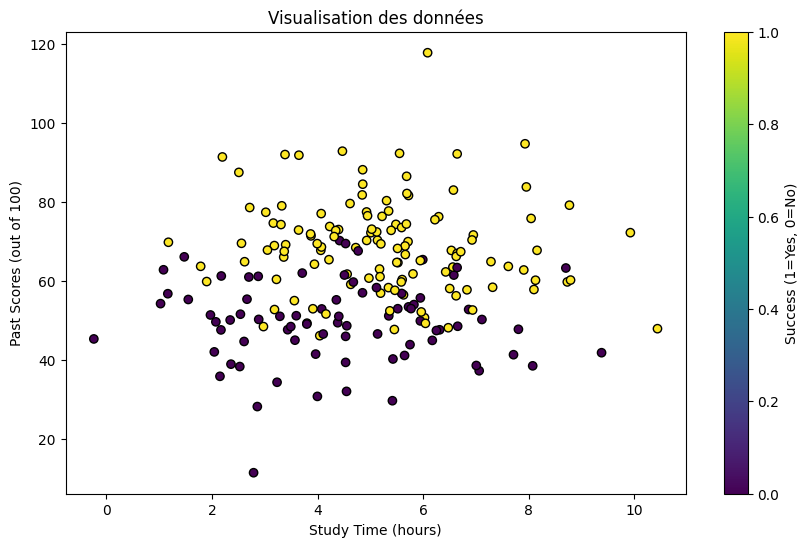

In [ ]:
# Charger le jeu de données
data = pd.read_csv("student_data.csv")
# Statistiques descriptives
print(data.describe())
# Visualisation des données
plt.figure(figsize=(10, 6))
plt.scatter(data['study_time'], data['past_scores'], c=data['success'],
cmap='viridis', edgecolor='k')
plt.colorbar(label='Success (1=Yes, 0=No)')
plt.xlabel('Study Time (hours)')
plt.ylabel('Past Scores (out of 100)')
plt.title('Visualisation des données')
plt.show()

**Étape 3 : Préparation des données**

In [ ]:
from sklearn.model_selection import train_test_split
# Variables indépendantes (X) et dépendante (y)
X = data[['study_time', 'past_scores']]
y = data['success']
# Division en ensembles d'entraînement et de test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y,
test_size=0.2, random_state=42)
print(f"Taille de l'ensemble d'entraînement : {X_train.shape[0]}")
print(f"Taille de l'ensemble de test : {X_test.shape[0]}")

Taille de l'ensemble d'entraînement : 160
Taille de l'ensemble de test : 40


**Étape 3 : Préparation des données**

In [ ]:
from sklearn.linear_model import LogisticRegression
# Créer et entraîner le modèle
model = LogisticRegression()
model.fit(X_train, y_train)
# Afficher les coefficients
print("Coefficients :", model.coef_)
print("Intercept :", model.intercept_)

Coefficients : [[0.41829555 0.19033676]]
Intercept : [-12.86330307]


**Étape 4 : Entraînement du modèle de régression logistique**

In [ ]:
from sklearn.linear_model import LogisticRegression
# Créer et entraîner le modèle
model = LogisticRegression()
model.fit(X_train, y_train)
# Afficher les coefficients
print("Coefficients :", model.coef_)
print("Intercept :", model.intercept_)

Coefficients : [[0.41829555 0.19033676]]
Intercept : [-12.86330307]


**Étape 5 : Évaluation du modèle**

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# Prédictions
y_pred = model.predict(X_test)
# Évaluation
print("Précision :", accuracy_score(y_test, y_pred))
print("\nMatrice de confusion :\n", confusion_matrix(y_test, y_pred))
print("\nRapport de classification :\n", classification_report(y_test, y_pred))

Précision : 0.775

Matrice de confusion :
 [[11  3]
 [ 6 20]]

Rapport de classification :
               precision    recall  f1-score   support

           0       0.65      0.79      0.71        14
           1       0.87      0.77      0.82        26

    accuracy                           0.78        40
   macro avg       0.76      0.78      0.76        40
weighted avg       0.79      0.78      0.78        40



**Étape 6 : Visualisation des résultats**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


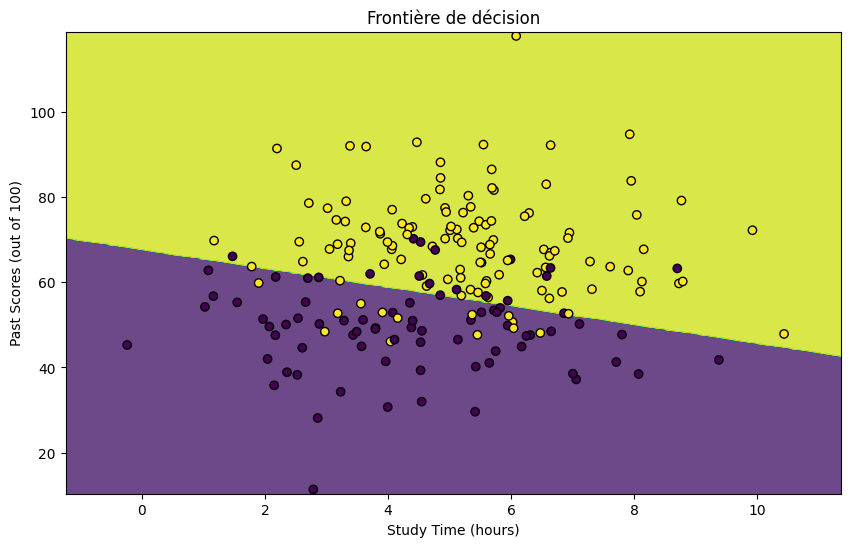

In [ ]:
# Visualisation de la frontière de décision
x_min, x_max = X['study_time'].min() - 1, X['study_time'].max() + 1
y_min, y_max = X['past_scores'].min() - 1, X['past_scores'].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min,
y_max, 0.1))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap='viridis')
plt.scatter(data['study_time'], data['past_scores'], c=data['success'],
edgecolor='k', cmap='viridis')
plt.xlabel('Study Time (hours)')
plt.ylabel('Past Scores (out of 100)')
plt.title('Frontière de décision')
plt.show()